# Projekt 2 - rekonstrukcja zdjęć wykonanych przy słabym oświetleniu

Badamy, czy sieć U-Net potrafi odtworzyć poprawnie naświetlone zdjęcie na podstawie obrazu z symulowaną ekspozycją −3 EV i szumem matrycy. Korzystamy ze 100 pierwszych zdjęć wnętrz z aparatu Nikon D7000 w zbiorze RAISE. Pierwsze 72 obrazy służą do treningu, kolejne 8 do wyboru modelu, a ostatnie 20 do oceny końcowej. Punktem odniesienia jest wyrównanie histogramu.

In [1]:
%pip install -q rawpy imageio requests lpips scikit-image opencv-python-headless

In [2]:
from pathlib import Path
import random
import time

import cv2
import imageio.v3 as iio
import lpips
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rawpy
import requests
import torch
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

ROOT = Path.cwd()
CSV_PATH = ROOT / 'RAISE_258.csv'
DATA_DIR = ROOT / 'data' / 'RAISE_project2'
RAW_DIR = DATA_DIR / 'raw'
INPUT_DIR = DATA_DIR / 'input'
GT_DIR = DATA_DIR / 'gt'
RESULT_DIR = ROOT / 'results_raise'
for folder in (RAW_DIR, INPUT_DIR, GT_DIR, RESULT_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print('Urządzenie:', device)
print('Katalog roboczy:', ROOT)

Urządzenie: cpu
Katalog roboczy: /content


In [3]:
if not CSV_PATH.exists():
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        pass
if not CSV_PATH.exists():
    raise FileNotFoundError(f'Umieść RAISE_258.csv w {ROOT}')

catalog = pd.read_csv(CSV_PATH)
selected = catalog.loc[
    catalog['Device'].eq('Nikon D7000') &
    catalog['Keywords'].fillna('').str.contains('Indoor', case=False)
].head(100).reset_index(drop=True)
if len(selected) != 100:
    raise ValueError(f'Znaleziono tylko {len(selected)} zdjęć spełniających warunki')
ids = selected['File'].tolist()
train_ids, val_ids, test_ids = ids[:72], ids[72:80], ids[80:100]
print(f'Trening: {len(train_ids)}, walidacja: {len(val_ids)}, test: {len(test_ids)}')
print('Pierwszy:', ids[0], '| ostatni testowy:', ids[-1])

Trening: 72, walidacja: 8, test: 20
Pierwszy: rfcf40796t | ostatni testowy: r02e1abe2t


## Przygotowanie obrazów

Z każdego pliku NEF tworzymy parę obrazów. Ground truth otrzymujemy przez wywołanie `raw.postprocess(use_camera_wb=True, half_size=True)` z instrukcji. Obraz wejściowy powstaje z liniowego obrazu 16-bitowego: zmniejszamy jego wartości osiem razy, dodajemy szum Poissona (α = 0,001) i Gaussa (σ = 0,005), a następnie stosujemy korekcję gamma 2,2 i zapisujemy wynik w 8 bitach. Stałe ziarno generatora pozwala użyć tych samych obrazów wejściowych dla obu metod.

In [4]:
def download_nef(row):
    target = RAW_DIR / f"{row['File']}.NEF"
    if target.exists() and target.stat().st_size > 1_000_000:
        return target
    partial = target.with_suffix('.part')
    for attempt in range(3):
        try:
            with requests.get(row['NEF'], stream=True, timeout=(20, 180)) as response:
                response.raise_for_status()
                with partial.open('wb') as output:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            output.write(chunk)
            if partial.stat().st_size < 1_000_000:
                raise ValueError('Pobrany plik jest za mały')
            partial.replace(target)
            return target
        except (requests.RequestException, OSError, ValueError):
            partial.unlink(missing_ok=True)
            if attempt == 2:
                raise
            time.sleep(2 * (attempt + 1))

for _, row in tqdm(selected.iterrows(), total=len(selected), desc='RAISE NEF'):
    download_nef(row)

RAISE NEF:   0%|          | 0/100 [00:00<?, ?it/s]

RAW → pary obrazów:   0%|          | 0/100 [00:00<?, ?it/s]

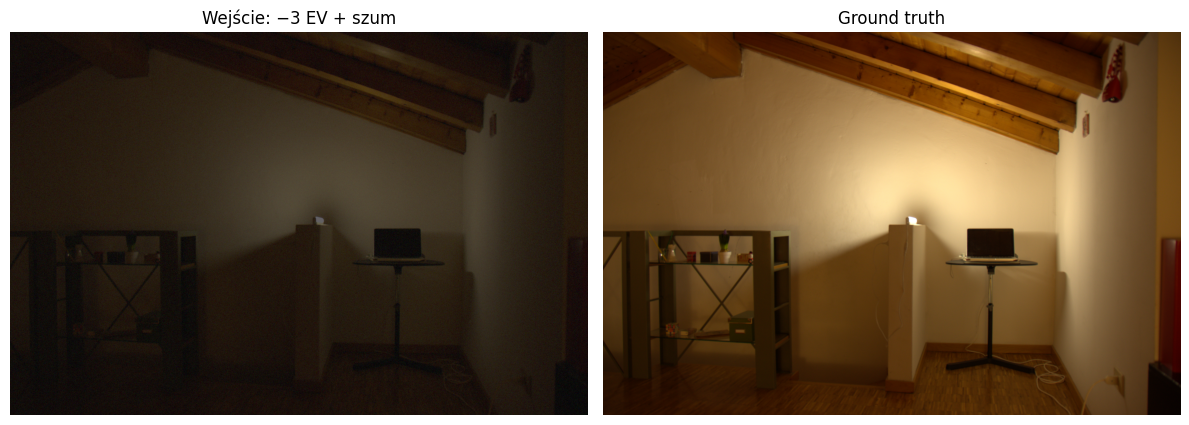

In [5]:
def reduce_exposure(linear_img, ev_shift=-3.0):
    return np.clip(linear_img * (2.0 ** ev_shift), 0.0, 1.0)


def add_physical_noise(linear_img, rng, alpha=0.001, sigma=0.005):
    photon = rng.poisson(linear_img / alpha).astype(np.float32) * alpha
    readout = rng.normal(0, sigma, linear_img.shape).astype(np.float32)
    return np.clip(photon + readout, 0.0, 1.0)


def apply_gamma_correction(img, gamma=2.2):
    return np.power(np.clip(img, 0.0, 1.0), 1.0 / gamma)


def convert_to_8bit(img):
    return np.rint(np.clip(img, 0.0, 1.0) * 255).astype(np.uint8)


def process_nef(image_id, seed):
    input_path = INPUT_DIR / f'{image_id}.png'
    gt_path = GT_DIR / f'{image_id}.png'
    if input_path.exists() and gt_path.exists():
        return
    with rawpy.imread(str(RAW_DIR / f'{image_id}.NEF')) as raw:
        gt = raw.postprocess(use_camera_wb=True, half_size=True)
        linear = raw.postprocess(use_camera_wb=True, gamma=(1, 1),
                                 no_auto_bright=True, output_bps=16,
                                 half_size=True).astype(np.float32) / 65535.0
    dark = reduce_exposure(linear, -3.0)
    noisy = add_physical_noise(dark, np.random.default_rng(seed))
    low_light = convert_to_8bit(apply_gamma_correction(noisy))
    iio.imwrite(gt_path, gt)
    iio.imwrite(input_path, low_light)


for i, image_id in enumerate(tqdm(ids, desc='RAW → pary obrazów')):
    process_nef(image_id, SEED + i)

sample_id = ids[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(iio.imread(INPUT_DIR / f'{sample_id}.png'))
axes[0].set_title('Wejście: −3 EV + szum')
axes[1].imshow(iio.imread(GT_DIR / f'{sample_id}.png'))
axes[1].set_title('Ground truth')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Sieć i uczenie

Zastosowaliśmy U-Net z trzema poziomami zmniejszania rozdzielczości i około 1,95 mln parametrów. Sieć uczy się na wycinkach 256 × 256 pikseli, losowo odbijanych w pionie i poziomie. Trening trwa 30 epok z funkcją straty L1 i optymalizatorem Adam (learning rate 0,0002). Do oceny używamy wag z epoki o najmniejszym błędzie walidacyjnym.

In [6]:
PATCH = 256
BATCH_SIZE = 8
EPOCHS = 30
TRAIN_REPEATS = 8


def load_pair(image_id):
    low = np.asarray(Image.open(INPUT_DIR / f'{image_id}.png').convert('RGB'))
    gt = np.asarray(Image.open(GT_DIR / f'{image_id}.png').convert('RGB'))
    return low, gt


def to_tensor(image):
    return torch.from_numpy(np.ascontiguousarray(image.transpose(2, 0, 1))).float() / 255.0


class TrainPairs(Dataset):
    def __init__(self, image_ids, repeats):
        self.pairs = [load_pair(image_id) for image_id in tqdm(image_ids, desc='Ładowanie treningu')]
        self.repeats = repeats

    def __len__(self):
        return len(self.pairs) * self.repeats

    def __getitem__(self, index):
        low, gt = self.pairs[index % len(self.pairs)]
        h, w = low.shape[:2]
        y = random.randrange(h - PATCH + 1)
        x = random.randrange(w - PATCH + 1)
        low, gt = low[y:y+PATCH, x:x+PATCH], gt[y:y+PATCH, x:x+PATCH]
        if random.random() < 0.5:
            low, gt = low[:, ::-1], gt[:, ::-1]
        if random.random() < 0.5:
            low, gt = low[::-1], gt[::-1]
        return to_tensor(low), to_tensor(gt)


class ValPairs(Dataset):
    def __init__(self, image_ids):
        self.pairs = [load_pair(image_id) for image_id in tqdm(image_ids, desc='Ładowanie walidacji')]

    def __len__(self):
        return 4 * len(self.pairs)

    def __getitem__(self, index):
        low, gt = self.pairs[index // 4]
        h, w = low.shape[:2]
        positions = [(0, 0), (0, w-PATCH), (h-PATCH, 0), (h-PATCH, w-PATCH)]
        y, x = positions[index % 4]
        return to_tensor(low[y:y+PATCH, x:x+PATCH]), to_tensor(gt[y:y+PATCH, x:x+PATCH])


train_loader = DataLoader(TrainPairs(train_ids, TRAIN_REPEATS), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=0, pin_memory=device.type == 'cuda')
val_loader = DataLoader(ValPairs(val_ids), batch_size=BATCH_SIZE,
                        num_workers=0, pin_memory=device.type == 'cuda')
print('Partie treningowe:', len(train_loader), '| walidacyjne:', len(val_loader))

Ładowanie treningu:   0%|          | 0/72 [00:00<?, ?it/s]

Ładowanie walidacji:   0%|          | 0/8 [00:00<?, ?it/s]

Partie treningowe: 72 | walidacyjne: 4


In [7]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class UNet(nn.Module):
    def __init__(self, base=32):
        super().__init__()
        self.down1 = ConvBlock(3, base)
        self.down2 = ConvBlock(base, base * 2)
        self.down3 = ConvBlock(base * 2, base * 4)
        self.middle = ConvBlock(base * 4, base * 8)
        self.up3 = ConvBlock(base * 12, base * 4)
        self.up2 = ConvBlock(base * 6, base * 2)
        self.up1 = ConvBlock(base * 3, base)
        self.pool = nn.MaxPool2d(2)
        self.head = nn.Conv2d(base, 3, 1)

    def forward(self, x):
        a = self.down1(x)
        b = self.down2(self.pool(a))
        c = self.down3(self.pool(b))
        z = self.middle(self.pool(c))
        z = nn.functional.interpolate(z, size=c.shape[-2:], mode='bilinear', align_corners=False)
        z = self.up3(torch.cat([z, c], dim=1))
        z = nn.functional.interpolate(z, size=b.shape[-2:], mode='bilinear', align_corners=False)
        z = self.up2(torch.cat([z, b], dim=1))
        z = nn.functional.interpolate(z, size=a.shape[-2:], mode='bilinear', align_corners=False)
        return torch.sigmoid(self.head(self.up1(torch.cat([z, a], dim=1))))


model = UNet().to(device)
print(f'Parametry: {sum(p.numel() for p in model.parameters()):,}')

Parametry: 1,946,947


Epoka 1/30:   0%|          | 0/72 [00:00<?, ?it/s]

01: train L1=0.2069, val L1=0.2153, best=0.2153


Epoka 2/30:   0%|          | 0/72 [00:00<?, ?it/s]

02: train L1=0.1360, val L1=0.2018, best=0.2018


Epoka 3/30:   0%|          | 0/72 [00:00<?, ?it/s]

03: train L1=0.1204, val L1=0.1761, best=0.1761


... (50 outputs left out)

Epoka 29/30:   0%|          | 0/72 [00:00<?, ?it/s]

29: train L1=0.0668, val L1=0.1511, best=0.1417


Epoka 30/30:   0%|          | 0/72 [00:00<?, ?it/s]

30: train L1=0.0706, val L1=0.1641, best=0.1417


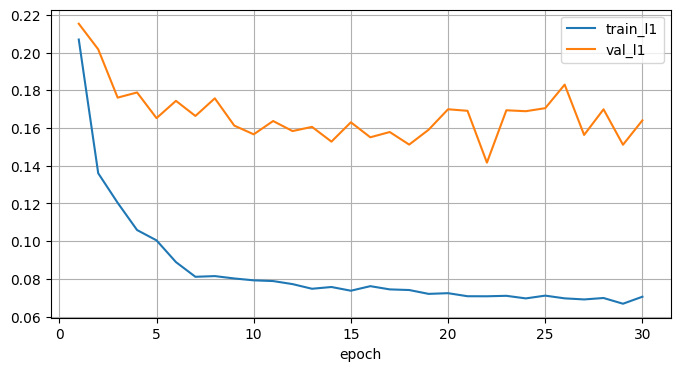

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=2e-4)
criterion = nn.L1Loss()
checkpoint = RESULT_DIR / 'unet_best.pt'
best_val = float('inf')
history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_sum = 0.0
    for low, gt in tqdm(train_loader, desc=f'Epoka {epoch}/{EPOCHS}', leave=False):
        low, gt = low.to(device), gt.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(low), gt)
        loss.backward()
        optimizer.step()
        train_sum += loss.item() * len(low)

    model.eval()
    val_sum = 0.0
    with torch.inference_mode():
        for low, gt in val_loader:
            low, gt = low.to(device), gt.to(device)
            val_sum += criterion(model(low), gt).item() * len(low)
    train_loss = train_sum / len(train_loader.dataset)
    val_loss = val_sum / len(val_loader.dataset)
    history.append({'epoch': epoch, 'train_l1': train_loss, 'val_l1': val_loss})
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), checkpoint)
    print(f'{epoch:02d}: train L1={train_loss:.4f}, val L1={val_loss:.4f}, best={best_val:.4f}')

history_df = pd.DataFrame(history)
history_df.to_csv(RESULT_DIR / 'history.csv', index=False)
history_df.plot(x='epoch', y=['train_l1', 'val_l1'], figsize=(8, 4), grid=True)
plt.show()

Najniższy błąd walidacyjny wyniósł 0,1417 w 22. epoce. Błąd treningowy dalej malał, ale walidacyjny wahał się i później nie poprawił tego wyniku. Dlatego do testu wybraliśmy zapisane wagi z 22. epoki.

## Porównanie na zbiorze testowym

Baseline wyrównuje histogram kanału jasności Y w przestrzeni YCrCb. U-Net przetwarza całe zdjęcia w nakładających się wycinkach. PSNR, SSIM i LPIPS obliczamy względem ground truth dla każdego z 20 zdjęć, a w tabeli pokazujemy średnie.

In [9]:
def equalize_histogram(rgb):
    ycrcb = cv2.cvtColor(rgb, cv2.COLOR_RGB2YCrCb)
    ycrcb[:, :, 0] = cv2.equalizeHist(ycrcb[:, :, 0])
    return cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2RGB)


def tile_starts(length, tile=256, stride=224):
    starts = list(range(0, length - tile + 1, stride))
    if starts[-1] != length - tile:
        starts.append(length - tile)
    return starts


@torch.inference_mode()
def predict_full(rgb, tile=256, batch_size=8):
    h, w = rgb.shape[:2]
    positions = [(y, x) for y in tile_starts(h, tile) for x in tile_starts(w, tile)]
    total = np.zeros((h, w, 3), dtype=np.float32)
    count = np.zeros((h, w, 1), dtype=np.float32)
    for start in range(0, len(positions), batch_size):
        batch_positions = positions[start:start + batch_size]
        patches = torch.stack([to_tensor(rgb[y:y+tile, x:x+tile]) for y, x in batch_positions]).to(device)
        outputs = model(patches).permute(0, 2, 3, 1).cpu().numpy()
        for (y, x), output in zip(batch_positions, outputs):
            total[y:y+tile, x:x+tile] += output
            count[y:y+tile, x:x+tile] += 1
    return np.rint(np.clip(total / count, 0, 1) * 255).astype(np.uint8)


model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
model.eval()
perceptual = lpips.LPIPS(net='alex').to(device).eval()


@torch.inference_mode()
def score(pred, gt):
    pred_float, gt_float = pred.astype(np.float32) / 255, gt.astype(np.float32) / 255
    pred_lp = to_tensor(pred).unsqueeze(0).to(device) * 2 - 1
    gt_lp = to_tensor(gt).unsqueeze(0).to(device) * 2 - 1
    return {
        'PSNR': peak_signal_noise_ratio(gt_float, pred_float, data_range=1.0),
        'SSIM': structural_similarity(gt_float, pred_float, data_range=1.0, channel_axis=2),
        'LPIPS': perceptual(pred_lp, gt_lp).item(),
        'clipped_%': 100 * np.mean(pred >= 250),
        'color_error': np.mean(np.abs(pred_float.mean((0, 1)) - gt_float.mean((0, 1)))),
    }


rows = []
for image_id in tqdm(test_ids, desc='Test — 20 zdjęć'):
    low, gt = load_pair(image_id)
    baseline = equalize_histogram(low)
    network = predict_full(low)
    iio.imwrite(RESULT_DIR / f'{image_id}_baseline.png', baseline)
    iio.imwrite(RESULT_DIR / f'{image_id}_network.png', network)
    for method, pred in [('baseline', baseline), ('network', network)]:
        rows.append({'image': image_id, 'method': method, **score(pred, gt)})

scores = pd.DataFrame(rows)
scores.to_csv(RESULT_DIR / 'test_metrics.csv', index=False)
summary = scores.groupby('method')[['PSNR', 'SSIM', 'LPIPS']].mean().loc[['baseline', 'network']]
display(summary.round(4))

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 155MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


Test — 20 zdjęć:   0%|          | 0/20 [00:00<?, ?it/s]

,PSNR,SSIM,LPIPS
method,,,
baseline,11.3147,0.1524,1.0770
network,20.7083,0.5671,0.5291


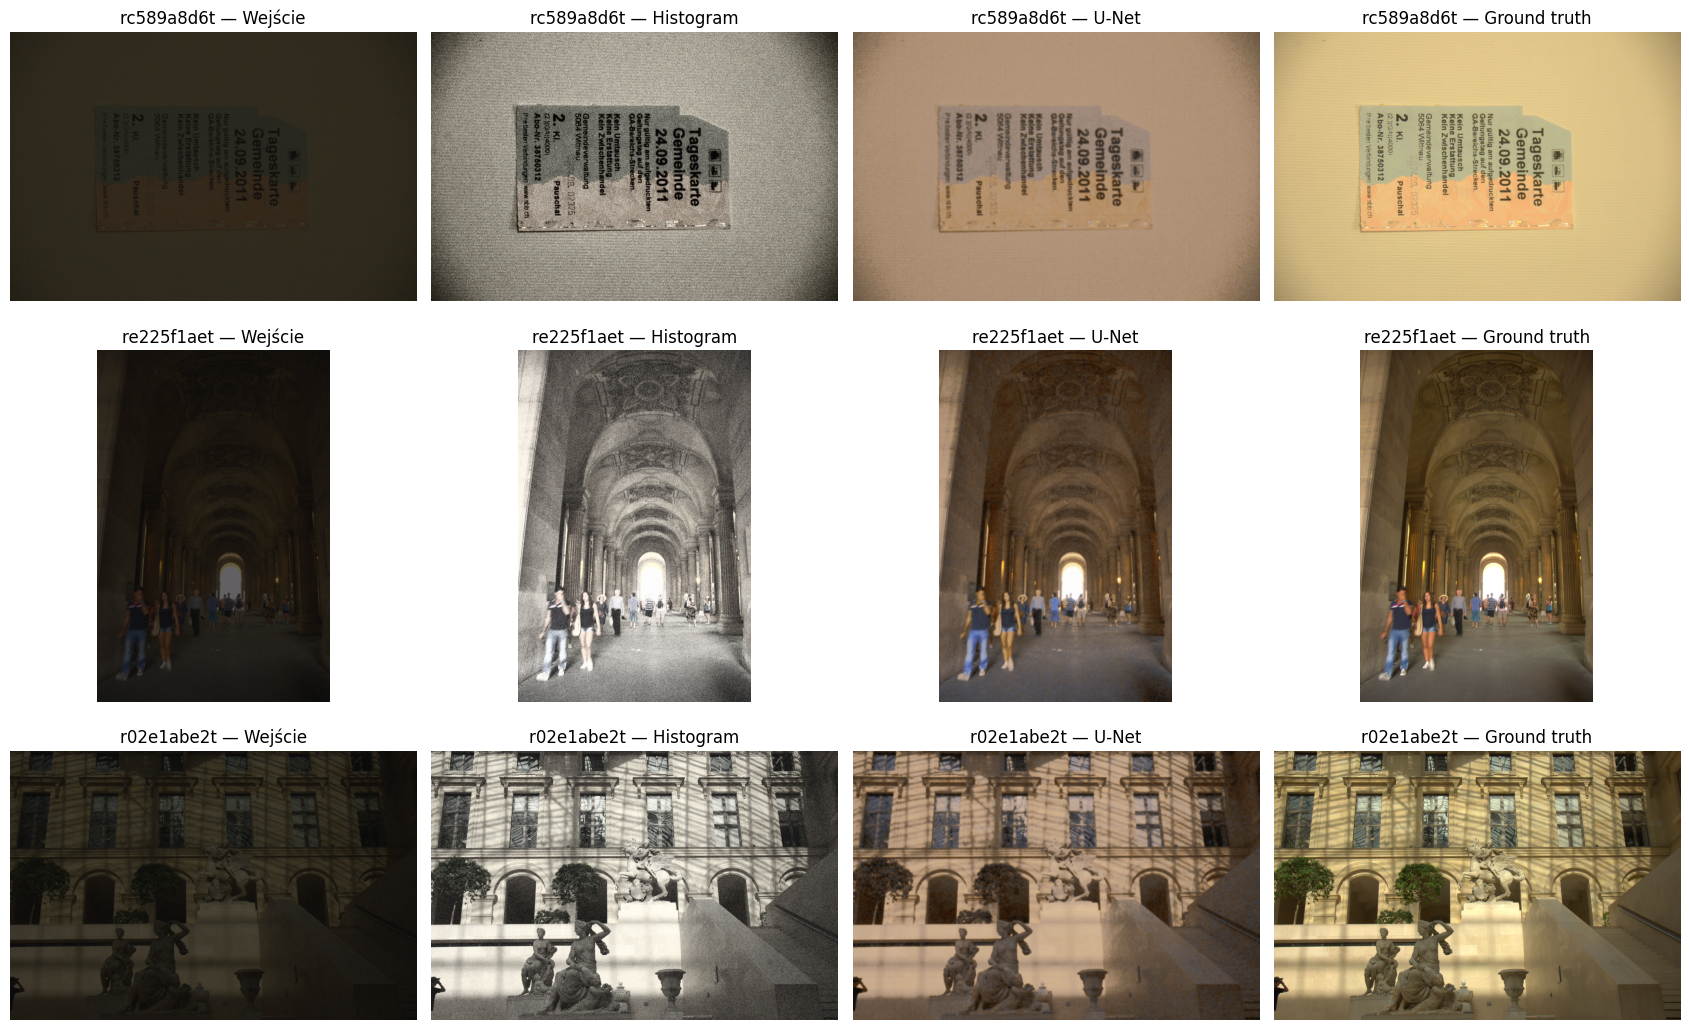

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(17, 11))
for row, image_id in enumerate([test_ids[0], test_ids[9], test_ids[19]]):
    low, gt = load_pair(image_id)
    baseline = iio.imread(RESULT_DIR / f'{image_id}_baseline.png')
    network = iio.imread(RESULT_DIR / f'{image_id}_network.png')
    for ax, (title, image) in zip(axes[row], [('Wejście', low), ('Histogram', baseline),
                                               ('U-Net', network), ('Ground truth', gt)]):
        ax.imshow(image)
        ax.set_title(f'{image_id} — {title}')
        ax.axis('off')
plt.tight_layout()
plt.show()

In [11]:
comparison = scores.pivot(index='image', columns='method', values=['PSNR', 'SSIM', 'LPIPS'])
for metric in ['PSNR', 'SSIM', 'LPIPS']:
    delta = summary.loc['network', metric] - summary.loc['baseline', metric]
    print(f'{metric}: sieć − baseline = {delta:+.4f}')
print('\nŚredni odsetek jasnych pikseli (>=250) i błąd średniego koloru:')
display(scores.groupby('method')[['clipped_%', 'color_error']].mean().round(4))
print('\nNajtrudniejsze zdjęcia dla sieci według PSNR:')
display(scores[scores.method == 'network'].nsmallest(3, 'PSNR')[['image', 'PSNR', 'SSIM', 'LPIPS']].round(4))
print('\nPSNR zdjęć testowych, oba warianty:')
display(comparison['PSNR'].round(2))

PSNR: sieć − baseline = +9.3936
SSIM: sieć − baseline = +0.4147
LPIPS: sieć − baseline = -0.5479

Średni odsetek jasnych pikseli (>=250) i błąd średniego koloru:


,clipped_%,color_error
method,,
baseline,2.8207,0.1999
network,0.4407,0.0634



Najtrudniejsze zdjęcia dla sieci według PSNR:


,image,PSNR,SSIM,LPIPS
37,redaf7d93t,15.3054,0.5329,0.6062
1,rc589a8d6t,15.5740,0.3447,0.7633
29,r35f565f8t,16.5878,0.3781,0.4401



PSNR zdjęć testowych, oba warianty:


method,baseline,network
image,,
r02e1abe2t,15.69,22.13
r19d72b0ct,15.40,23.45
r26241ddat,9.35,24.14
r2f910937t,5.92,24.06
r35f565f8t,8.24,16.59
r43b830fet,6.99,18.60
r5211d294t,14.56,20.16
r53dd949dt,10.55,21.57
r683da315t,11.89,20.64


## Wnioski

U-Net osiągnął średnio **20,71 dB PSNR, 0,567 SSIM i 0,529 LPIPS**, a wyrównanie histogramu **11,31 dB, 0,152 i 1,077**. Sieć ma wyższy PSNR na 19 z 20 zdjęć. Jedynym wyjątkiem jest `redaf7d93t`: 15,31 dB wobec 15,38 dB dla baseline'u.

Na pokazanych zdjęciach wyrównanie histogramu mocno wzmacnia szum i rozjaśnia także obszary, które powinny pozostać ciemne. Sieć lepiej zachowuje strukturę scen, ale czasem wygładza drobne detale oraz daje zbyt ciemny i zbyt ciepły obraz w porównaniu z ground truth. Jasne okno w korytarzu pozostaje trudnym przypadkiem. Średni udział wartości kanałów bliskich bieli (co najmniej 250/255) wynosi 2,82% dla baseline'u i 0,44% dla sieci; jest to prosty wskaźnik przepaleń, nie pełna ocena szczegółów w jasnych obszarach.

Wyniki spełniają cel porównania z metodą klasyczną. Największym ograniczeniem jest różnica między błędem treningowym a walidacyjnym oraz błędy jasności i barw widoczne mimo przewagi sieci w metrykach.

Zdjęcie `r02e1abe2t` pokazuje elewację, mimo że w katalogu RAISE ma kategorię `Indoor; buildings`. Pozostawiliśmy je w teście, ponieważ podział wynika z pierwszych 100 pozycji wskazanego katalogu, bez ręcznej zmiany kolejności.